# Mono-jet: inference with the released RACNN-ClassiFlow ensemble

This notebook shows the two examples of the paper's Figs 10 and 11, a high-yield and a low-yield parameter point, each in one signal region (SR) of the test set. For each it shows

* the $p_T$, $E\!\!\!/_T$ and $\eta$ histograms in the SR: signal + background, background, and signal;
* the ensemble posterior $q(m_\mathrm{DM}, g_\chi \mid \mathcal{D}_c, c)$ on the signal-plus-background ensemble and on a background-only ensemble of the same SR;
* the classifier output $P(s+b \mid \mathcal{D}_c, c)$, the logit $\Lambda$ and the posterior entropy $H$.

It uses the RACNN-ClassiFlow-$\mathcal{L}$ ensemble (3 of 5 runs, `weights/ensembles.json`); the paper figures use the $\Delta$ ensemble (`"best_model_ediff"` below). The test file has 2.9 million rows, so only the rows needed are read.

**Before running:** download the data with `python scripts/download.py --no-train` from the repository root (the weights are already in `weights/`).

In [10]:
import os, sys, json
import numpy as np
import torch
import matplotlib.pyplot as plt

REPO    = os.path.abspath("..")               # repository root (this notebook lives in monojet/)
DATA    = os.path.join(REPO, "data")          # datasets from Hugging Face, see scripts/download.py
WEIGHTS = os.path.join(REPO, "weights")       # trained weights, part of this repository
sys.path.insert(0, REPO)
import racnn_inference as ri

_, fd = ri.import_analysis("monojet")           # puts monojet/ on sys.path; fd = flexibledataset
import inference_plots as ip
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


In [11]:
CHECKPOINT = "best_model"            # "best_model_ediff" for the Delta ensemble of the paper figures
ensemble = ri.load_ensemble("monojet", "racnnclassiflows", CHECKPOINT, WEIGHTS, device)
print("ensemble runs:", json.load(open(f"{WEIGHTS}/ensembles.json"))["monojet"]["racnnclassiflows"][CHECKPOINT])

sub-manifold (0 - e2 - gggt) and intra-manifold flow (0 - g) options overwrite  upper_bound_for_widths  with  1
sub-manifold (0 - e2 - gggt) and intra-manifold flow (0 - g) options overwrite  lower_bound_for_widths  with  0.01
sub-manifold (0 - e2 - gggt) and intra-manifold flow (0 - g) options overwrite  fit_normalization  with  0
sub-manifold (0 - e2 - gggt) and intra-manifold flow (1 - g) options overwrite  upper_bound_for_widths  with  1
sub-manifold (0 - e2 - gggt) and intra-manifold flow (1 - g) options overwrite  lower_bound_for_widths  with  0.01
sub-manifold (0 - e2 - gggt) and intra-manifold flow (1 - g) options overwrite  fit_normalization  with  0
sub-manifold (0 - e2 - gggt) and intra-manifold flow (2 - g) options overwrite  upper_bound_for_widths  with  1
sub-manifold (0 - e2 - gggt) and intra-manifold flow (2 - g) options overwrite  lower_bound_for_widths  with  0.01
sub-manifold (0 - e2 - gggt) and intra-manifold flow (2 - g) options overwrite  fit_normalization  with  

## Paper Figs 10 and 11

$\theta$ and the SR of each figure: hard cuts on $p_T$ ($E\!\!\!/_T$ shares it) and $|\eta|$, and the histogram windows of the three observables.

m_DM = 200 GeV, g_chi = 2.85: test.h5 rows [156659, 1361864] (signal+background, background only)


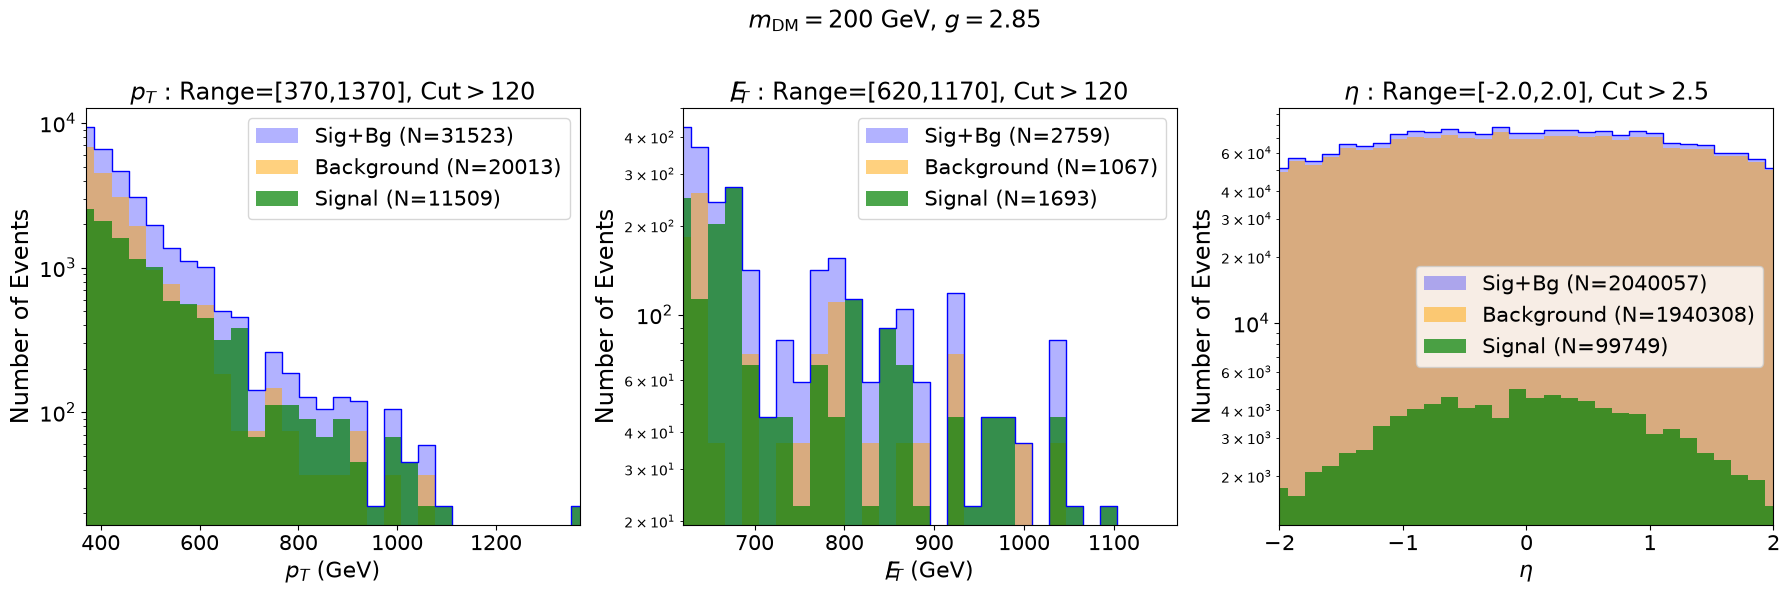

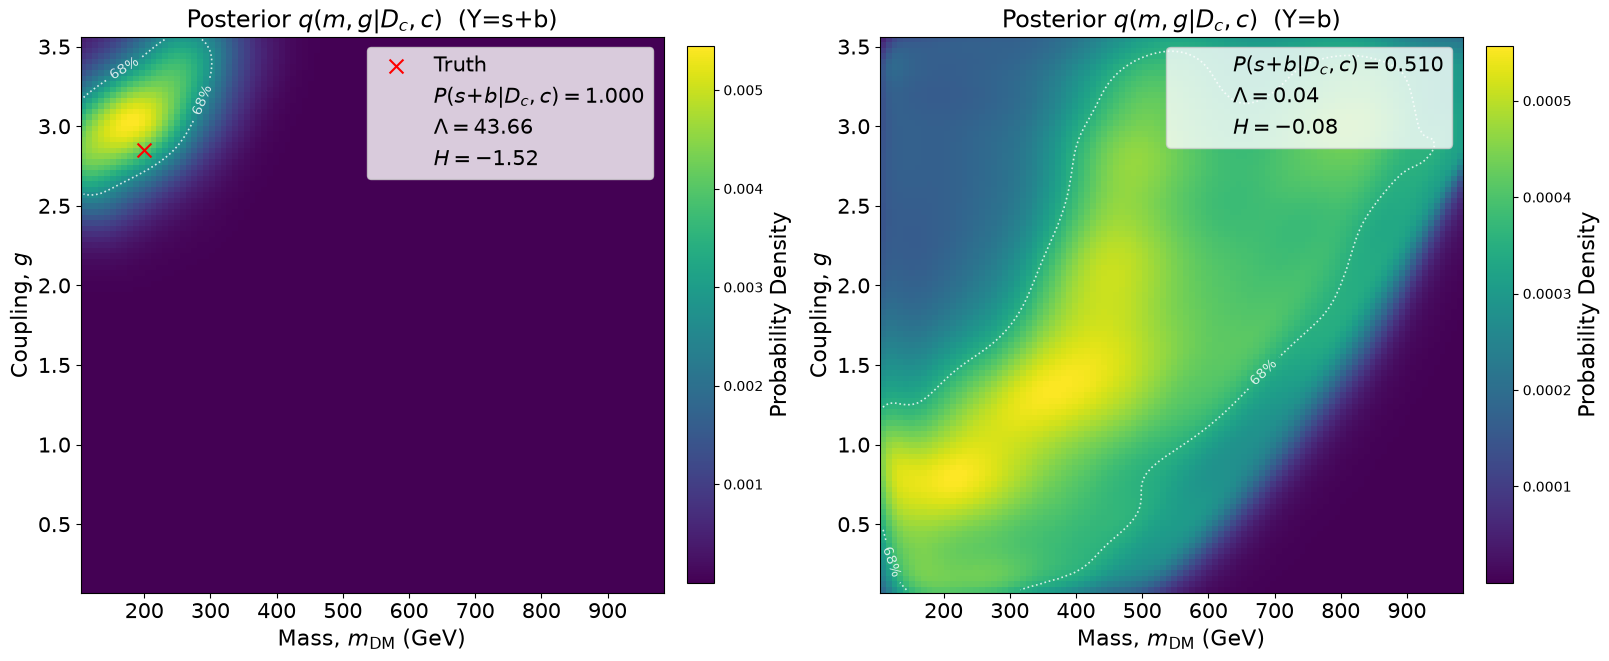

m_DM = 500 GeV, g_chi = 1.1: test.h5 rows [409431, 1764700] (signal+background, background only)


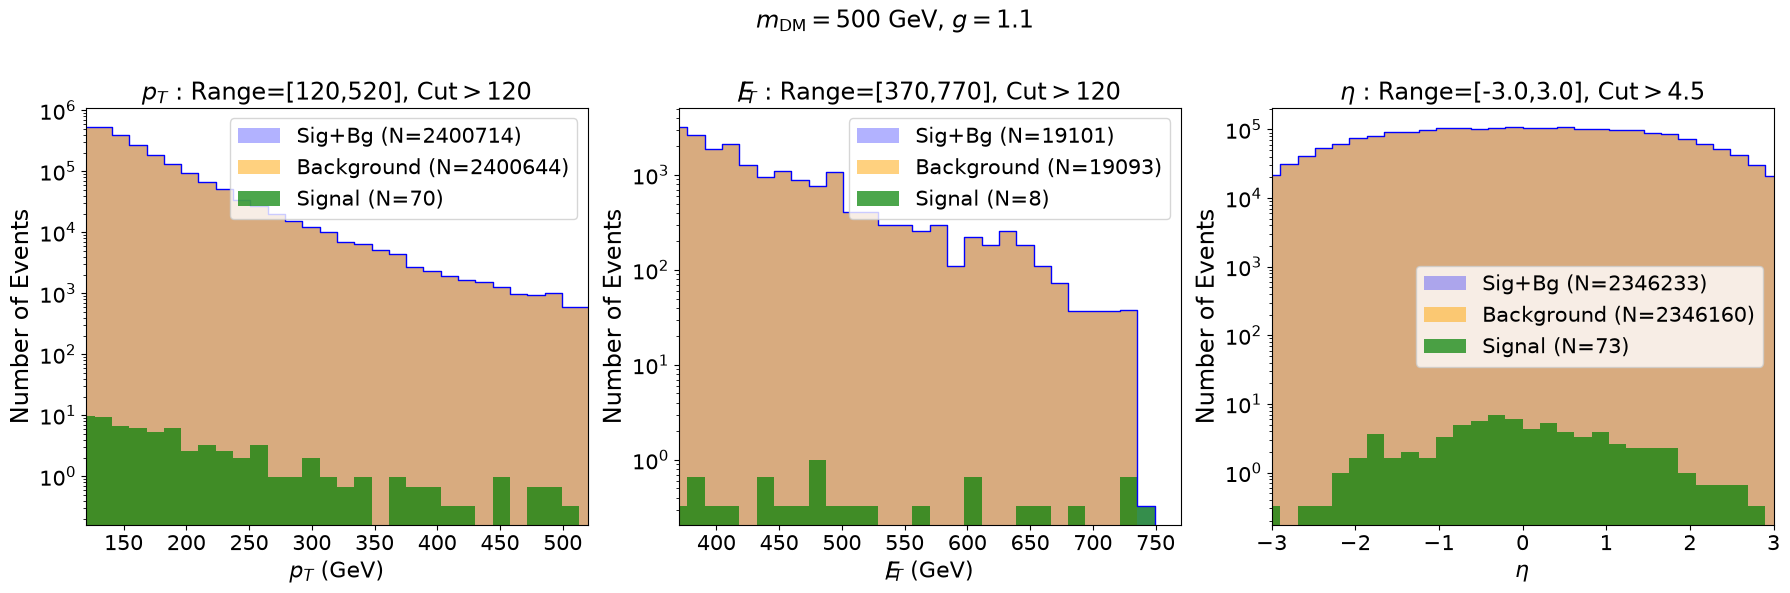

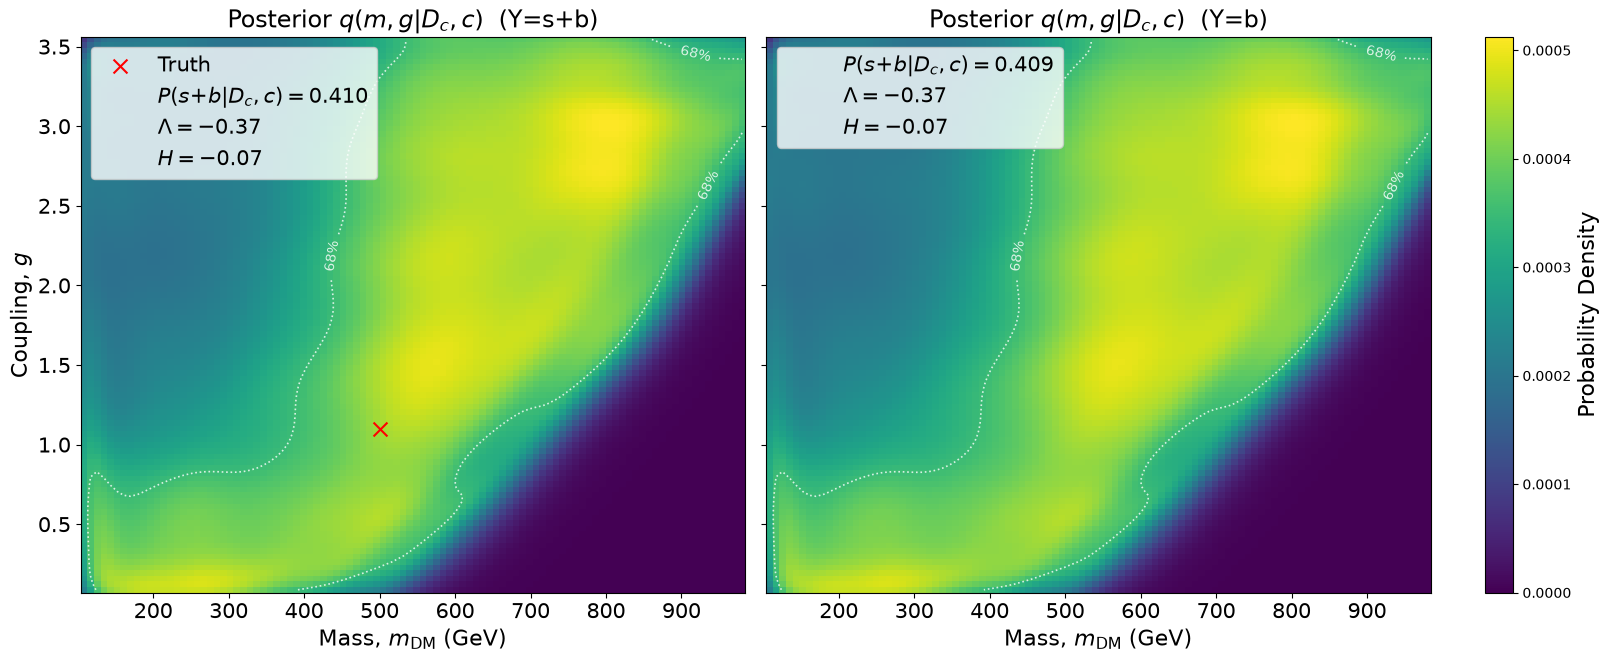

In [12]:
EXAMPLES = [   # (m_DM [GeV], g_chi, SR, shared colour bar)
    (200, 2.85, dict(PT_CUT=120, ETA_CUT=2.5, PT_LOW=370, PT_UP=1370, MET_LOW=620, MET_UP=1170, ETA_LOW=-2.0, ETA_UP=2.0), False),
    (500, 1.10, dict(PT_CUT=120, ETA_CUT=4.5, PT_LOW=120, PT_UP=520, MET_LOW=370, MET_UP=770, ETA_LOW=-3.0, ETA_UP=3.0), True),
]
for m_dm, g_chi, sr, share in EXAMPLES:
    pair, rows = ip.find_example(f"{DATA}/monojet/test.h5", m_dm, g_chi, sr)
    print(f"m_DM = {m_dm} GeV, g_chi = {g_chi}: test.h5 rows {rows.tolist()} (signal+background, background only)")
    ip.plot_data(pair, sr, m_dm, g_chi); plt.show()
    ip.plot_posteriors(ensemble, pair, m_dm, g_chi, share_colorbar=share, device=device); plt.show()

## Your own example

Any $\theta$ of the test grid (`test.h5`, or `resttest.h5` for the remaining points) and any SR of the SR family described in the paper (Appendix C). `find_example` returns `(None, None)` if the combination is not in the file.

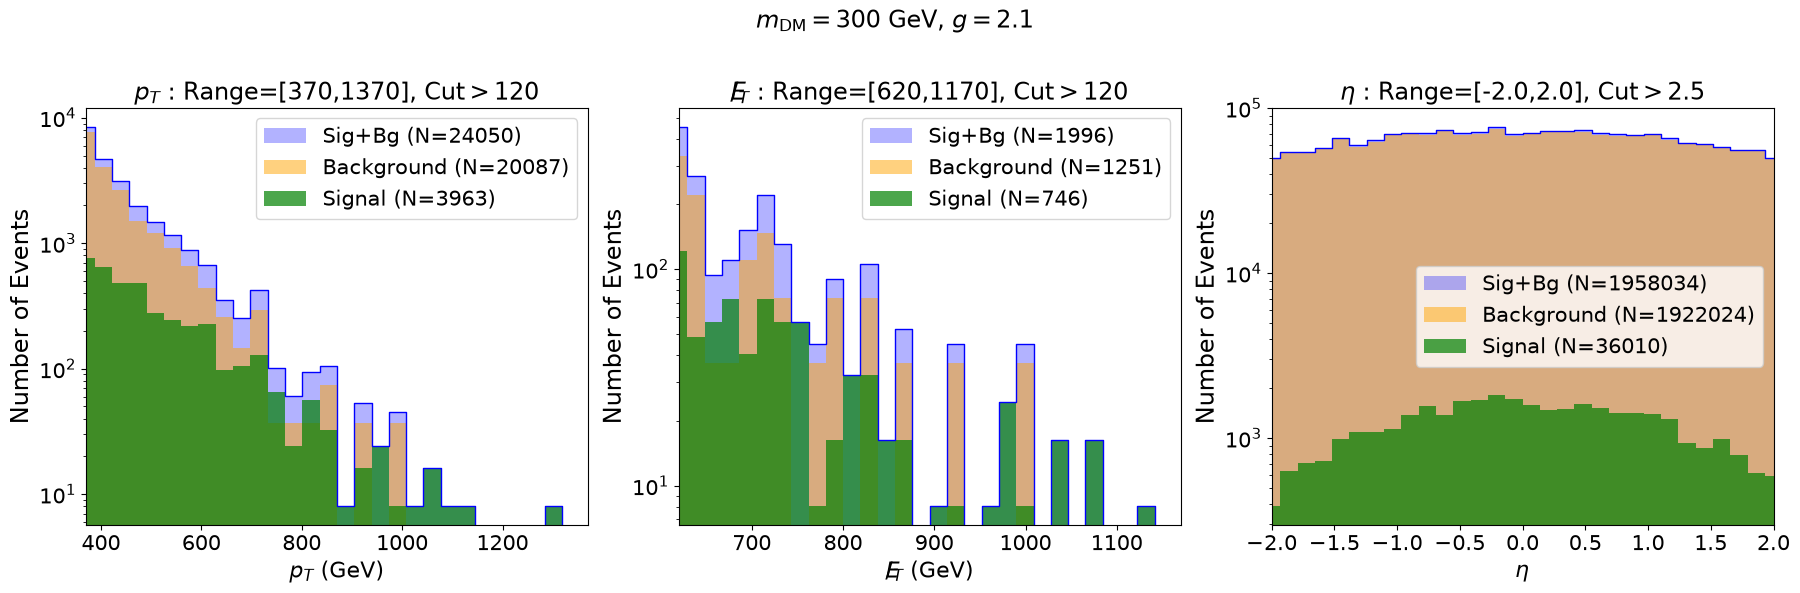

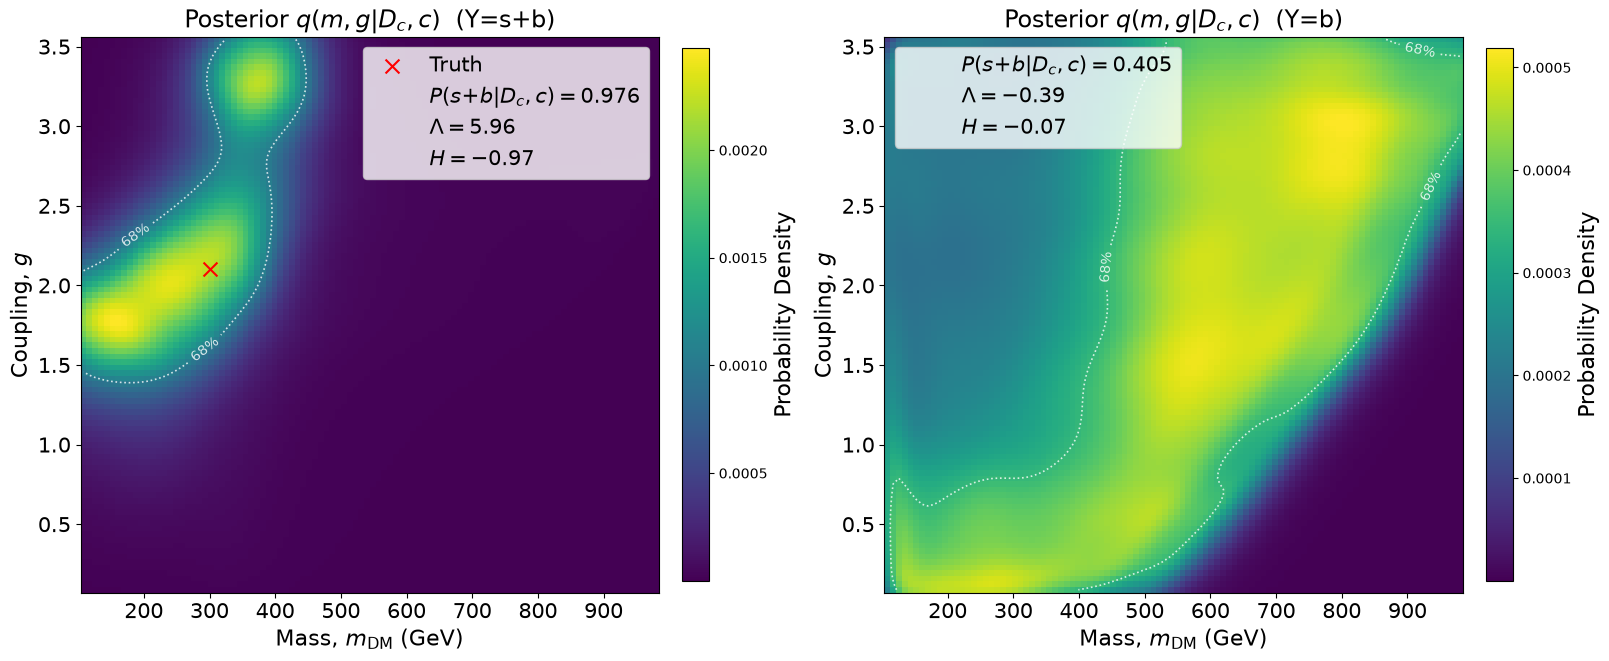

In [13]:
m_dm, g_chi = 300, 2.1
sr = dict(PT_CUT=120, ETA_CUT=2.5, PT_LOW=370, PT_UP=1370, MET_LOW=620, MET_UP=1170, ETA_LOW=-2.0, ETA_UP=2.0)
pair, rows = ip.find_example(f"{DATA}/monojet/test.h5", m_dm, g_chi, sr)
if pair is None:
    pair, rows = ip.find_example(f"{DATA}/monojet/resttest.h5", m_dm, g_chi, sr)
ip.plot_data(pair, sr, m_dm, g_chi); plt.show()
ip.plot_posteriors(ensemble, pair, m_dm, g_chi, device=device); plt.show()